In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.decomposition import PCA

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("Dataset shape:", df.shape)
display(df.head())
print("\nClass distribution:")
display(df["species"].value_counts().rename_axis("species").to_frame("count"))

Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Class distribution:


,count
species,
setosa,50
versicolor,50
virginica,50


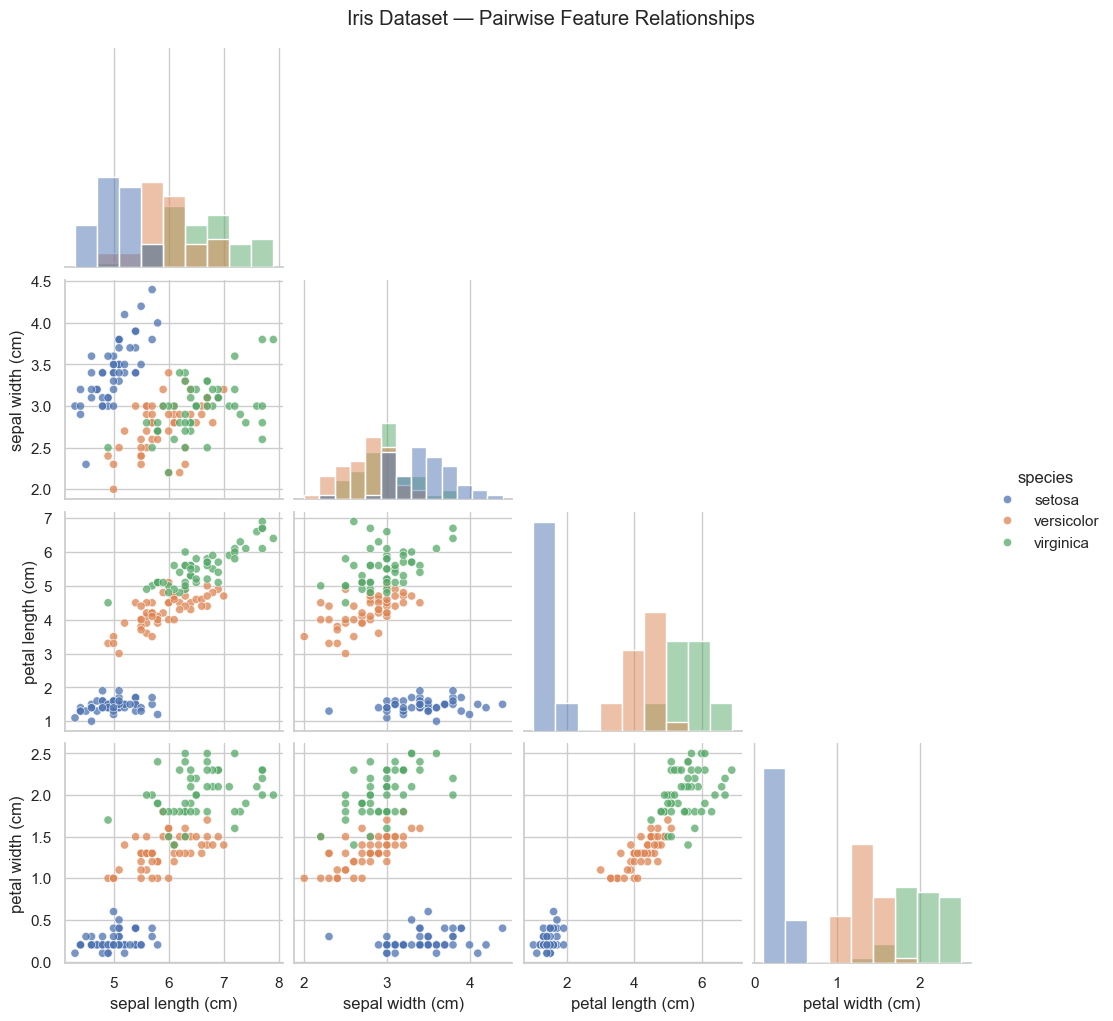

In [2]:
# Pairplot: pairwise feature relationships, colored by species
pair_plot = sns.pairplot(
    df,
    hue="species",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.75, "s": 35}
)
pair_plot.fig.suptitle("Iris Dataset — Pairwise Feature Relationships", y=1.02)
plt.show()

In [3]:
X = df[iris.feature_names]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {X_train.shape[0]} ({X_train.shape[0] / len(df):.0%})")
print(f"Testing samples:  {X_test.shape[0]} ({X_test.shape[0] / len(df):.0%})")

print("\nTraining class counts:")
display(y_train.value_counts().sort_index().to_frame("count"))

print("Testing class counts:")
display(y_test.value_counts().sort_index().to_frame("count"))

Training samples: 120 (80%)
Testing samples:  30 (20%)

Training class counts:


,count
species,
setosa,40
versicolor,40
virginica,40


Testing class counts:


,count
species,
setosa,10
versicolor,10
virginica,10


In [4]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training feature means (approximately 0):")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nScaled training feature standard deviations (approximately 1):")
print(np.round(X_train_scaled.std(axis=0), 3))

Scaled training feature means (approximately 0):
[-0. -0.  0.  0.]

Scaled training feature standard deviations (approximately 1):
[1. 1. 1. 1.]


In [5]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    )
}

for model_name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{model_name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete


In [6]:
results = []
predictions = {}

for model_name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

    print(f"\n{'=' * 65}")
    print(f"Classification Report — {model_name}")
    print("=" * 65)
    print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.style.format("{:.4f}").highlight_max(axis=0, color="#d8f0d2"))


Classification Report — Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Classification Report — Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


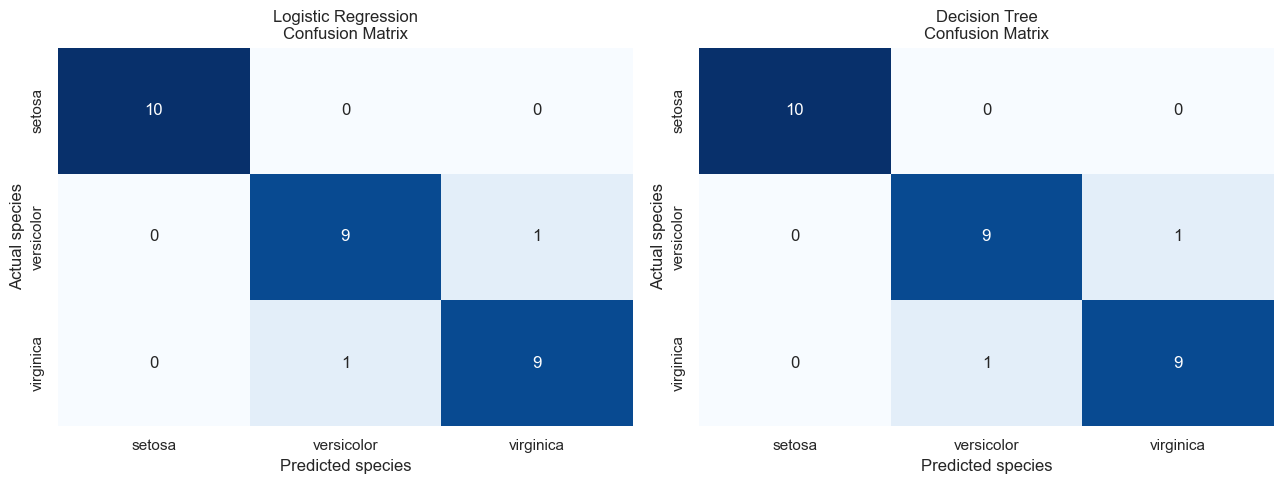

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=iris.target_names)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )
    ax.set_title(f"{model_name}\nConfusion Matrix")
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")

plt.tight_layout()
plt.show()

Explained variance by first two principal components: 95.74%


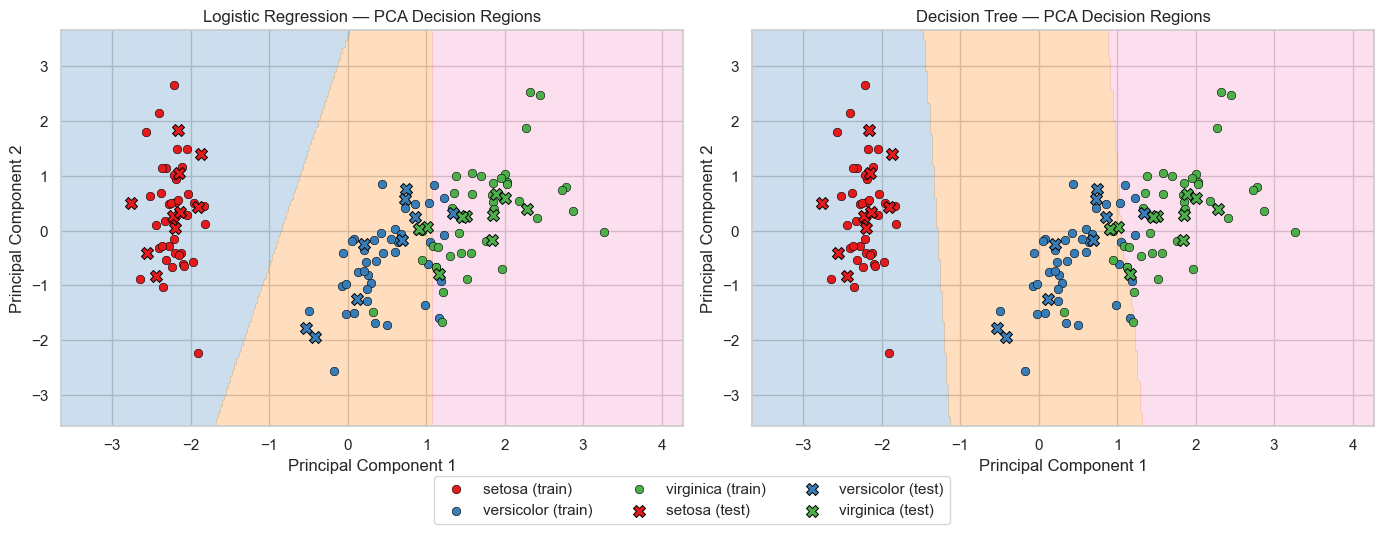

In [8]:
# Fit PCA on the scaled training features only
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Explained variance by first two principal components:",
      f"{pca.explained_variance_ratio_.sum():.2%}")

# Build a mesh in the 2D PCA plane
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
mesh_pca = np.c_[xx.ravel(), yy.ravel()]

# Convert PCA mesh points back to the four-dimensional scaled feature space
mesh_scaled_4d = pca.inverse_transform(mesh_pca)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette("Set1", n_colors=3)
class_to_num = {name: i for i, name in enumerate(iris.target_names)}
y_train_num = y_train.astype(str).map(class_to_num).to_numpy()
y_test_num = y_test.astype(str).map(class_to_num).to_numpy()

for ax, (model_name, model) in zip(axes, models.items()):
    mesh_predictions = model.predict(mesh_scaled_4d)
    mesh_predictions_num = pd.Series(mesh_predictions.astype(str)).map(class_to_num).to_numpy()
    Z = mesh_predictions_num.reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        alpha=0.25,
        levels=np.arange(-0.5, 3.5, 1),
        cmap="Set1"
    )

    # Training points
    for class_name, class_idx in class_to_num.items():
        mask = y_train.astype(str).to_numpy() == class_name
        ax.scatter(
            X_train_pca[mask, 0],
            X_train_pca[mask, 1],
            color=palette[class_idx],
            marker="o",
            edgecolor="black",
            linewidth=0.4,
            s=38,
            label=f"{class_name} (train)"
        )

    # Test points are marked with black-edged X symbols
    for class_name, class_idx in class_to_num.items():
        mask = y_test.astype(str).to_numpy() == class_name
        ax.scatter(
            X_test_pca[mask, 0],
            X_test_pca[mask, 1],
            color=palette[class_idx],
            marker="X",
            edgecolor="black",
            linewidth=0.7,
            s=75,
            label=f"{class_name} (test)"
        )

    ax.set_title(f"{model_name} — PCA Decision Regions")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.show()

In [9]:
summary = results_df.sort_values("F1-score (weighted)", ascending=False)
display(summary.style.format("{:.4f}"))

best_model_name = summary.index[0]
print(f"Best model by weighted F1-score: {best_model_name}")
print("\nNote: The ranking is based on this fixed 80/20 test split. For a more robust estimate,")
print("consider repeating evaluation with stratified cross-validation.")

,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


Best model by weighted F1-score: Logistic Regression

Note: The ranking is based on this fixed 80/20 test split. For a more robust estimate,
consider repeating evaluation with stratified cross-validation.
